# Comparare performanță pe testul din alt set de date

**1. Încărcare dataset**

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("orvile/neh-ut-oct-dataset")

print("Path to dataset files:", path)

100%|██████████| 4.67G/4.67G [00:46<00:00, 108MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/orvile/neh-ut-oct-dataset/versions/1


In [6]:
import os
from collections import Counter

root_path = path

counter = Counter()

for root, dirs, files in os.walk(root_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")):
            try:
                label = file.split("_")[-1].split(".")[0]
                counter[label] += 1
            except:
                pass

print("Număr imagini per clasă:")
for label, count in counter.items():
    print(f"{label}: {count}")

print("\nTotal imagini:", sum(counter.values()))

Număr imagini per clasă:
Normal: 8136
NOrmal: 221
Drusen: 4812
normal: 220
CNV: 3234
DRusen: 176
drusen: 4

Total imagini: 16803


In [27]:
import os
import shutil

root_path = path
output_path = "/content/OCT_3_classes"

classes = ["NORMAL", "DRUSEN", "CNV"]

for cls in classes:
    os.makedirs(os.path.join(output_path, cls), exist_ok=True)

counters = {
    "NORMAL": 1,
    "DRUSEN": 1,
    "CNV": 1
}

for root, dirs, files in os.walk(root_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")):

            label_raw = file.split("_")[-1].split(".")[0].lower()

            if "normal" in label_raw:
                label = "NORMAL"
            elif "drusen" in label_raw:
                label = "DRUSEN"
            elif "cnv" in label_raw:
                label = "CNV"
            else:
                continue

            src = os.path.join(root, file)

            new_name = f"{counters[label]}.jpg"
            dst = os.path.join(output_path, label, new_name)

            shutil.copy2(src, dst)

            counters[label] += 1

print("Dataset:", output_path)

Dataset: /content/OCT_3_classes


In [29]:
import os

clean_path ="/content/OCT_3_classes"

total = 0

for cls in ["NORMAL", "DRUSEN", "CNV"]:
    class_path = os.path.join(clean_path, cls)
    count = len(os.listdir(class_path))
    total += count
    print(f"{cls}: {count}")

print("\nTotal final:", total)

NORMAL: 8733
DRUSEN: 5020
CNV: 3265

Total final: 17018


# Model de clasificare a imaginilor OCT folosind MobileNetV2

**1. Încărcare model**

In [22]:
from tensorflow.keras.models import load_model

# Încarc modelul Keras
model_keras = load_model("/content/oct_cnn_model_MobileNetV2.h5")
model_keras.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,110 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 2 (12.00 B)

**2. Testare**

In [33]:
import numpy as np
from tqdm import tqdm
import tensorflow as tf
import cv2
import os

TARGET_SIZE = (224, 224)
BATCH_SIZE = 32
class_names = ["CNV", "DRUSEN", "NORMAL"]

def preprocess_oct(image):
    # Convert grayscale
    if len(image.shape) == 3 and image.shape[-1] == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    image = cv2.resize(image, TARGET_SIZE)
    image = cv2.medianBlur(image, 3)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    image = clahe.apply(image)
    image = image.astype("float32") / 255.0
    # stack grayscale → 3 channel
    return np.stack([image, image, image], axis=-1)

ROOT = "/content/OCT_3_classes"
VALID_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

paths, labels = [], []

for idx, cls in enumerate(class_names):
    folder = os.path.join(ROOT, cls)
    for root_dir, _, files in os.walk(folder):
        for fname in files:
            if fname.lower().endswith(VALID_EXT):
                paths.append(os.path.join(root_dir, fname))
                labels.append(idx)

labels = np.array(labels)
print(f"Total images found: {len(paths)}")

# Predict batch-by-batch
keras_preds = []

keras_preds = []
valid_labels = []

for i in tqdm(range(0, len(paths), BATCH_SIZE), desc="Predicting batches"):
    batch_paths = paths[i:i+BATCH_SIZE]
    batch_labels = labels[i:i+BATCH_SIZE]
    X_batch = []
    valid_batch_labels = []

    for p, lbl in zip(batch_paths, batch_labels):
        img = cv2.imread(p)
        if img is None:
            print(f"Warning: could not read image {p}")
            continue
        img = preprocess_oct(img)
        X_batch.append(img)
        valid_batch_labels.append(lbl)

    if len(X_batch) == 0:
        continue

    X_batch = np.array(X_batch)
    preds = np.argmax(model_keras.predict(X_batch, verbose=0), axis=1)
    keras_preds.extend(preds)
    valid_labels.extend(valid_batch_labels)

keras_preds = np.array(keras_preds)
valid_labels = np.array(valid_labels)

print("Preds length:", len(keras_preds))
print("Labels length:", len(valid_labels))

keras_preds = np.array(keras_preds)

Total images found: 17018


Predicting batches:  82%|████████▏ | 436/532 [02:34<00:30,  3.12it/s]

Predicting batches: 100%|██████████| 532/532 [03:07<00:00,  2.84it/s]

Preds length: 17017
Labels length: 17017


**3. Afișare rezultate**

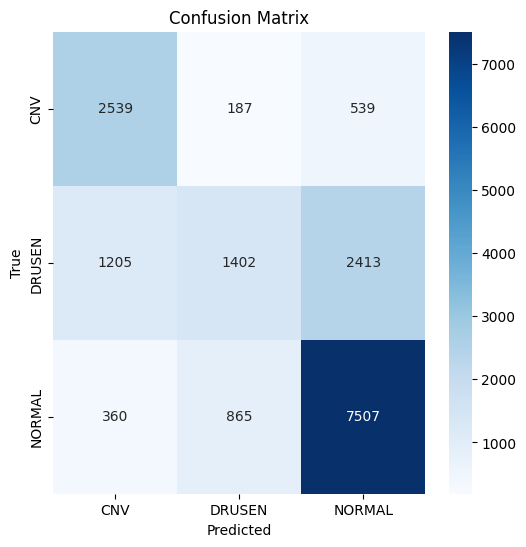


=== Accuracy per class ===
CNV: 0.7776
DRUSEN: 0.2793
NORMAL: 0.8597

Classification Report:

              precision    recall  f1-score   support

         CNV       0.62      0.78      0.69      3265
      DRUSEN       0.57      0.28      0.38      5020
      NORMAL       0.72      0.86      0.78      8732

    accuracy                           0.67     17017
   macro avg       0.64      0.64      0.62     17017
weighted avg       0.66      0.67      0.64     17017

Test Accuracy: 67.27%


In [36]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

y_true = valid_labels
y_pred = keras_preds

class_names_filtered = ["CNV", "DRUSEN", "NORMAL"]
keep_idx = [0,1,2]

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=keep_idx)

plt.figure(figsize=(6,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names_filtered,
            yticklabels=class_names_filtered)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# Accuracy per clasă
class_acc = cm.diagonal() / cm.sum(axis=1)
print("\n=== Accuracy per class ===")
for cls, acc in zip(class_names_filtered, class_acc):
    print(f"{cls}: {acc:.4f}")

# Classification report
report = classification_report(y_true, y_pred, labels=keep_idx, target_names=class_names_filtered)
print("\nClassification Report:\n")
print(report)

# Accuracy global
acc_total = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {acc_total*100:.2f}%")

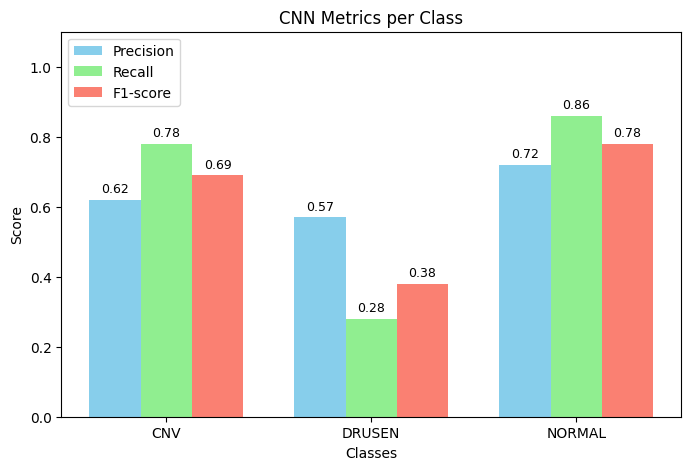

In [37]:
import matplotlib.pyplot as plt
import numpy as np

classes = ["CNV",  "DRUSEN", "NORMAL"]

precision = [0.62,  0.57, 0.72]
recall    = [0.78,  0.28, 0.86]
f1_score  = [0.69,  0.38, 0.78]

x = np.arange(len(classes))
width = 0.25

fig, ax = plt.subplots(figsize=(8,5))
rects1 = ax.bar(x - width, precision, width, label='Precision', color='skyblue')
rects2 = ax.bar(x, recall, width, label='Recall', color='lightgreen')
rects3 = ax.bar(x + width, f1_score, width, label='F1-score', color='salmon')

ax.set_ylabel('Score')
ax.set_xlabel('Classes')
ax.set_title('CNN Metrics per Class')
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0,1.1)
ax.legend()

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width()/2, height),
                    xytext=(0,3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.show()


# Model de clasificare a imaginilor OCT folosind ResNet18

**1. Încărcare model**

In [38]:
import torch
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

pt_model = torch.load(
    '/content/oct_cnn_model_ResNet18.pth',
    map_location=device,
    weights_only=False
)

pt_model.eval()


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

**2. Testare**

In [43]:
valid_paths = []
valid_labels = []

for p, lbl in zip(paths, labels):
    try:
        img = Image.open(p).convert("RGB")
        valid_paths.append(p)
        valid_labels.append(lbl)
    except (OSError, IOError):
        print(f"Warning: skipping corrupted image {p}")

valid_labels = np.array(valid_labels)

# Dataset + DataLoader
dataset_pt = OCTDataset(valid_paths, valid_labels, transform=transform_pt)
dataloader_pt = DataLoader(dataset_pt, batch_size=BATCH_SIZE, shuffle=False)

KeyboardInterrupt: 

In [46]:
import torch
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from tqdm import tqdm
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Parametri
BATCH_SIZE = 32
class_names = ["CNV", "DRUSEN", "NORMAL"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Dataset PyTorch
class OCTDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        label = self.labels[idx]
        return img, label

# Transform
transform_pt = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# fișiere corupte
valid_paths = []
valid_labels = []
corrupt_count = 0

for p, lbl in zip(paths, labels):
    try:
        img = Image.open(p).convert("RGB")
        valid_paths.append(p)
        valid_labels.append(lbl)
    except (OSError, IOError):
        corrupt_count += 1
        print(f"Warning: skipping corrupted image {p}")

valid_labels = np.array(valid_labels)

print(f"Total imagini originale: {len(paths)}")
print(f"Imagini corupte sărite: {corrupt_count}")
print(f"Imagini valide procesate: {len(valid_paths)} ({len(valid_paths)}/{len(paths)})")

# Dataset + DataLoader
dataset_pt = OCTDataset(valid_paths, valid_labels, transform=transform_pt)
dataloader_pt = DataLoader(dataset_pt, batch_size=BATCH_SIZE, shuffle=False)

# Model
pt_model.to(DEVICE)
pt_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for imgs, lbls in tqdm(dataloader_pt, desc="Predicting PyTorch batches"):
        imgs = imgs.to(DEVICE)
        outputs = pt_model(imgs)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(lbls.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

print(f"\nPredictii efectuate: {len(all_preds)}/{len(paths)}")

Total imagini originale: 17018
Imagini corupte sărite: 1
Imagini valide procesate: 17017 (17017/17018)


Predicting PyTorch batches: 100%|██████████| 532/532 [02:35<00:00,  3.43it/s]


Predictii efectuate: 17017/17018


**3. Afișare rezultate**

Test Accuracy : 76.65%


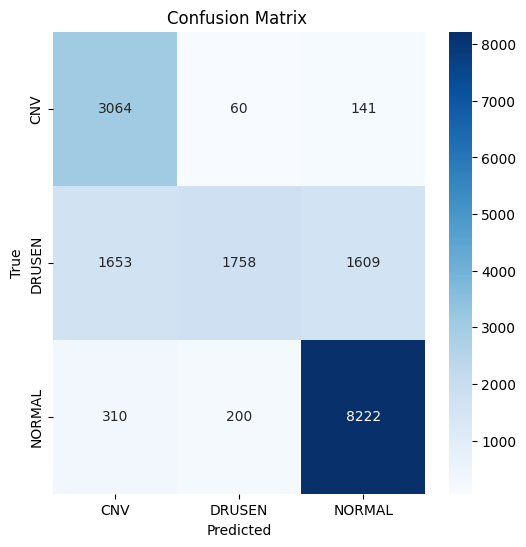


Classification Report:

              precision    recall  f1-score   support

         CNV       0.61      0.94      0.74      3265
      DRUSEN       0.87      0.35      0.50      5020
      NORMAL       0.82      0.94      0.88      8732

    accuracy                           0.77     17017
   macro avg       0.77      0.74      0.71     17017
weighted avg       0.80      0.77      0.74     17017


=== Acuratețe per clasă  ===
CNV: 0.9384
DRUSEN: 0.3502
NORMAL: 0.9416


In [47]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

keep_idx = [0, 1, 2]
class_names_filtered = ["CNV", "DRUSEN", "NORMAL"]

# Filtrez valorile
all_labels_filtered = all_labels[np.isin(all_labels, keep_idx)]
all_preds_filtered  = all_preds[np.isin(all_labels, keep_idx)]

# Acuratețe globală
acc_total_filtered = accuracy_score(all_labels_filtered, all_preds_filtered)
print(f"Test Accuracy : {acc_total_filtered*100:.2f}%")

# Matrice confuzie
cm_filtered = confusion_matrix(all_labels_filtered, all_preds_filtered, labels=keep_idx)
plt.figure(figsize=(6,6))
sns.heatmap(cm_filtered, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names_filtered, yticklabels=class_names_filtered)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix ")
plt.show()

# Raport clasificare
report_filtered = classification_report(all_labels_filtered, all_preds_filtered, labels=keep_idx, target_names=class_names_filtered)
print("\nClassification Report:\n")
print(report_filtered)

# Acuratețe per clasă
class_acc_filtered = cm_filtered.diagonal() / cm_filtered.sum(axis=1)
print("\n=== Acuratețe per clasă  ===")
for cls, acc in zip(class_names_filtered, class_acc_filtered):
    print(f"{cls}: {acc:.4f}")


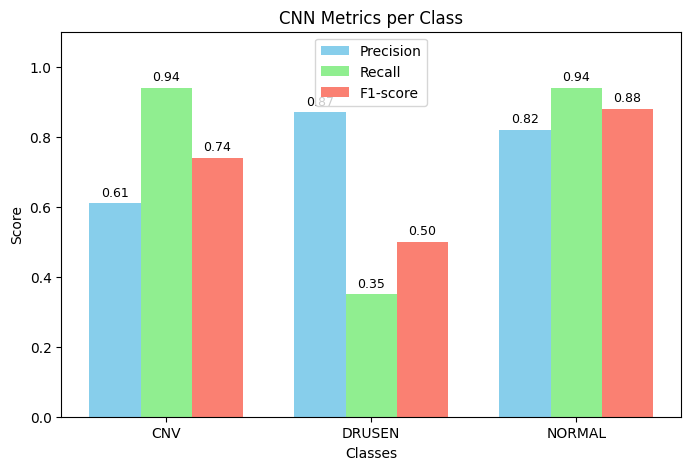

In [48]:
import matplotlib.pyplot as plt
import numpy as np

classes = ["CNV",  "DRUSEN", "NORMAL"]

precision = [0.61,  0.87, 0.82]
recall    = [0.94,  0.35, 0.94]
f1_score  = [0.74,  0.50, 0.88]

x = np.arange(len(classes))
width = 0.25

fig, ax = plt.subplots(figsize=(8,5))
rects1 = ax.bar(x - width, precision, width, label='Precision', color='skyblue')
rects2 = ax.bar(x, recall, width, label='Recall', color='lightgreen')
rects3 = ax.bar(x + width, f1_score, width, label='F1-score', color='salmon')

ax.set_ylabel('Score')
ax.set_xlabel('Classes')
ax.set_title('CNN Metrics per Class')
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0,1.1)
ax.legend()

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width()/2, height),
                    xytext=(0,3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.show()
